In [15]:
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import BaggingClassifier
from sklearn.metrics import accuracy_score
import pandas as pd
import numpy as np
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from imblearn.over_sampling import SMOTE
from collections import Counter
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import RandomForestClassifier
import xgboost as xgb
import lightgbm as lgb
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# 加载鸢尾花数据集
iris = load_iris()
X = iris.data
y = iris.target

# 模拟不平衡数据集，这里假设只保留类别0和1，并且让类别0样本数远少于类别1
X = X[y != 2]
y = y[y != 2]
# 随机选择部分类别0的样本，减少其数量
np.random.seed(42)
class_0_indices = np.where(y == 0)[0]
selected_indices = np.random.choice(class_0_indices, size=10, replace=False)
other_indices = np.where(y != 0)[0]
new_indices = np.concatenate([selected_indices, other_indices])
X = X[new_indices]
y = y[new_indices]

# 划分训练集和测试集
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 打印原始训练集和测试集的基本信息
print("原始训练集样本数:", len(X_train))
print("原始测试集样本数:", len(X_test))
print("原始训练集类别分布:", Counter(y_train))
print("原始测试集类别分布:", Counter(y_test))

# 使用SMOTE进行过采样
smote = SMOTE(random_state=42)
X_train_resampled, y_train_resampled = smote.fit_resample(X_train, y_train)

# 打印过采样后训练集的类别分布
print("过采样后训练集类别分布:", Counter(y_train_resampled))

# 定义评估函数
def evaluate_model(model, X_test, y_test):
    y_pred = model.predict(X_test)
    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred)
    recall = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    return accuracy, precision, recall, f1

# 逻辑回归模型
lr_model = LogisticRegression(random_state=42)
lr_model.fit(X_train_resampled, y_train_resampled)
lr_accuracy, lr_precision, lr_recall, lr_f1 = evaluate_model(lr_model, X_test, y_test)
print("\n逻辑回归模型评估结果:")
print(f"准确率: {lr_accuracy:.4f}")
print(f"精确率: {lr_precision:.4f}")
print(f"召回率: {lr_recall:.4f}")
print(f"F1 分数: {lr_f1:.4f}")

# SVM模型
svm_model = SVC(random_state=42, C=1, kernel='linear')  # 调整模型复杂度
svm_model.fit(X_train_resampled, y_train_resampled)
svm_accuracy, svm_precision, svm_recall, svm_f1 = evaluate_model(svm_model, X_test, y_test)
print("\nSVM模型评估结果:")
print(f"准确率: {svm_accuracy:.4f}")
print(f"精确率: {svm_precision:.4f}")
print(f"召回率: {svm_recall:.4f}")
print(f"F1 分数: {svm_f1:.4f}")

# 朴素贝叶斯模型
nb_model = GaussianNB()
nb_model.fit(X_train_resampled, y_train_resampled)
nb_accuracy, nb_precision, nb_recall, nb_f1 = evaluate_model(nb_model, X_test, y_test)
print("\n朴素贝叶斯模型评估结果:")
print(f"准确率: {nb_accuracy:.4f}")
print(f"精确率: {nb_precision:.4f}")
print(f"召回率: {nb_recall:.4f}")
print(f"F1 分数: {nb_f1:.4f}")

# 随机森林模型
rf_model = RandomForestClassifier(random_state=42, n_estimators=50, max_depth=3)  # 调整模型复杂度
rf_model.fit(X_train_resampled, y_train_resampled)
rf_accuracy, rf_precision, rf_recall, rf_f1 = evaluate_model(rf_model, X_test, y_test)
print("\n随机森林模型评估结果:")
print(f"准确率: {rf_accuracy:.4f}")
print(f"精确率: {rf_precision:.4f}")
print(f"召回率: {rf_recall:.4f}")
print(f"F1 分数: {rf_f1:.4f}")

# XGBoost模型
xgb_model = xgb.XGBClassifier(random_state=42, n_estimators=50, max_depth=3)  # 调整模型复杂度
xgb_model.fit(X_train_resampled, y_train_resampled)
xgb_accuracy, xgb_precision, xgb_recall, xgb_f1 = evaluate_model(xgb_model, X_test, y_test)
print("\nXGBoost模型评估结果:")
print(f"准确率: {xgb_accuracy:.4f}")
print(f"精确率: {xgb_precision:.4f}")
print(f"召回率: {xgb_recall:.4f}")
print(f"F1 分数: {xgb_f1:.4f}")

# LightGBM模型
lgb_model = lgb.LGBMClassifier(random_state=42, n_estimators=50, max_depth=3)  # 调整模型复杂度
lgb_model.fit(X_train_resampled, y_train_resampled)
lgb_accuracy, lgb_precision, lgb_recall, lgb_f1 = evaluate_model(lgb_model, X_test, y_test)
print("\nLightGBM模型评估结果:")
print(f"准确率: {lgb_accuracy:.4f}")
print(f"精确率: {lgb_precision:.4f}")
print(f"召回率: {lgb_recall:.4f}")
print(f"F1 分数: {lgb_f1:.4f}")

原始训练集样本数: 48
原始测试集样本数: 12
原始训练集类别分布: Counter({1: 40, 0: 8})
原始测试集类别分布: Counter({1: 10, 0: 2})
过采样后训练集类别分布: Counter({1: 40, 0: 40})

逻辑回归模型评估结果:
准确率: 1.0000
精确率: 1.0000
召回率: 1.0000
F1 分数: 1.0000

SVM模型评估结果:
准确率: 1.0000
精确率: 1.0000
召回率: 1.0000
F1 分数: 1.0000

朴素贝叶斯模型评估结果:
准确率: 0.9167
精确率: 0.9091
召回率: 1.0000
F1 分数: 0.9524

随机森林模型评估结果:
准确率: 1.0000
精确率: 1.0000
召回率: 1.0000
F1 分数: 1.0000

XGBoost模型评估结果:
准确率: 1.0000
精确率: 1.0000
召回率: 1.0000
F1 分数: 1.0000
[LightGBM] [Info] Number of positive: 40, number of negative: 40
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000022 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 82
[LightGBM] [Info] Number of data points in the train set: 80, number of used features: 4
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=0.000000
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with posit

In [16]:
# 朴素贝叶斯模型（使用Bagging优化）
from sklearn.ensemble import BaggingClassifier
from sklearn.naive_bayes import GaussianNB

# 创建朴素贝叶斯基分类器
base_nb_model = GaussianNB()

# 创建Bagging分类器，以朴素贝叶斯为基分类器
bagging_nb_model = BaggingClassifier(base_estimator=base_nb_model, n_estimators=10, random_state=42)

# 训练Bagging优化后的朴素贝叶斯模型
bagging_nb_model.fit(X_train_resampled, y_train_resampled)

# 评估Bagging优化后的朴素贝叶斯模型
bagging_nb_accuracy, bagging_nb_precision, bagging_nb_recall, bagging_nb_f1 = evaluate_model(bagging_nb_model, X_test, y_test)
print("\nBagging优化后的朴素贝叶斯模型评估结果:")
print(f"准确率: {bagging_nb_accuracy:.4f}")
print(f"精确率: {bagging_nb_precision:.4f}")
print(f"召回率: {bagging_nb_recall:.4f}")
print(f"F1 分数: {bagging_nb_f1:.4f}")


Bagging优化后的朴素贝叶斯模型评估结果:
准确率: 0.9167
精确率: 0.9091
召回率: 1.0000
F1 分数: 0.9524


c:\Users\73671\.conda\envs\vs\lib\site-packages\sklearn\ensemble\_base.py:156: FutureWarning: `base_estimator` was renamed to `estimator` in version 1.2 and will be removed in 1.4.
  warnings.warn(


c:\Users\73671\.conda\envs\vs\lib\site-packages\sklearn\ensemble\_base.py:156: FutureWarning: `base_estimator` was renamed to `estimator` in version 1.2 and will be removed in 1.4.
  warnings.warn(


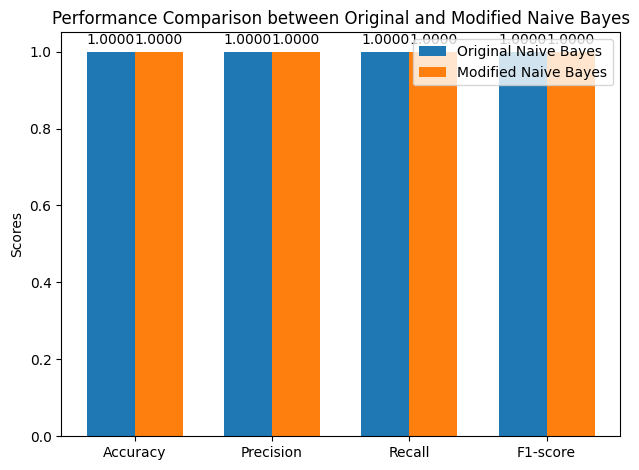

In [10]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import BaggingClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# 加载鸢尾花数据集
iris = load_iris()
X = iris.data
y = iris.target

# 划分训练集和测试集
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 原始朴素贝叶斯模型
original_model = GaussianNB()
original_model.fit(X_train, y_train)
original_y_pred = original_model.predict(X_test)

# 计算原始模型的评估指标
original_accuracy = accuracy_score(y_test, original_y_pred)
original_precision = precision_score(y_test, original_y_pred, average='weighted')
original_recall = recall_score(y_test, original_y_pred, average='weighted')
original_f1 = f1_score(y_test, original_y_pred, average='weighted')

# 修改后的朴素贝叶斯模型（特征缩放 + Bagging）
# 特征缩放
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 创建Bagging分类器
base_model = GaussianNB()
modified_model = BaggingClassifier(base_estimator=base_model, n_estimators=10, random_state=42)
modified_model.fit(X_train_scaled, y_train)
modified_y_pred = modified_model.predict(X_test_scaled)

# 计算修改后模型的评估指标
modified_accuracy = accuracy_score(y_test, modified_y_pred)
modified_precision = precision_score(y_test, modified_y_pred, average='weighted')
modified_recall = recall_score(y_test, modified_y_pred, average='weighted')
modified_f1 = f1_score(y_test, modified_y_pred, average='weighted')

# 可视化性能差异
metrics = ['Accuracy', 'Precision', 'Recall', 'F1-score']
original_scores = [original_accuracy, original_precision, original_recall, original_f1]
modified_scores = [modified_accuracy, modified_precision, modified_recall, modified_f1]

x = np.arange(len(metrics))  # 标签位置
width = 0.35  # 柱状图宽度

fig, ax = plt.subplots()
rects1 = ax.bar(x - width/2, original_scores, width, label='Original Naive Bayes')
rects2 = ax.bar(x + width/2, modified_scores, width, label='Modified Naive Bayes')

# 添加文本标签和标题
ax.set_ylabel('Scores')
ax.set_title('Performance Comparison between Original and Modified Naive Bayes')
ax.set_xticks(x)
ax.set_xticklabels(metrics)
ax.legend()

def autolabel(rects):
    """在每个柱子上添加数值标签"""
    for rect in rects:
        height = rect.get_height()
        ax.annotate('{:.4f}'.format(height),
                    xy=(rect.get_x() + rect.get_width() / 2, height),
                    xytext=(0, 3),  # 3 points vertical offset
                    textcoords="offset points",
                    ha='center', va='bottom')

autolabel(rects1)
autolabel(rects2)

fig.tight_layout()

plt.show()

In [26]:
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import BaggingClassifier
from sklearn.metrics import accuracy_score
import pandas as pd
import numpy as np
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from imblearn.over_sampling import SMOTE
from collections import Counter
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import RandomForestClassifier
import xgboost as xgb
import lightgbm as lgb
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# 加载鸢尾花数据集
iris = load_iris()
X = iris.data
y = iris.target

# 模拟不平衡数据集，这里假设只保留类别0和1，并且让类别0样本数远少于类别1
X = X[y != 2]
y = y[y != 2]
# 随机选择部分类别0的样本，减少其数量
np.random.seed(42)
class_0_indices = np.where(y == 0)[0]
selected_indices = np.random.choice(class_0_indices, size=10, replace=False)
other_indices = np.where(y != 0)[0]
new_indices = np.concatenate([selected_indices, other_indices])
X = X[new_indices]
y = y[new_indices]

# 划分训练集和测试集
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 打印原始训练集和测试集的基本信息
print("原始训练集样本数:", len(X_train))
print("原始测试集样本数:", len(X_test))
print("原始训练集类别分布:", Counter(y_train))
print("原始测试集类别分布:", Counter(y_test))

# 使用SMOTE进行过采样
smote = SMOTE(random_state=42)
X_train_resampled, y_train_resampled = smote.fit_resample(X_train, y_train)

# 打印过采样后训练集的类别分布
print("过采样后训练集类别分布:", Counter(y_train_resampled))

# 定义评估函数，修改 average 参数
def evaluate_model(model, X_test, y_test):
    y_pred = model.predict(X_test)
    accuracy = accuracy_score(y_test, y_pred)
    # 修改 average 参数为 'weighted'，你也可以选择 'micro' 或 'macro'
    precision = precision_score(y_test, y_pred, average='weighted')
    recall = recall_score(y_test, y_pred, average='weighted')
    f1 = f1_score(y_test, y_pred, average='weighted')
    return accuracy, precision, recall, f1

# 逻辑回归模型
lr_model = LogisticRegression(random_state=42)
lr_model.fit(X_train_resampled, y_train_resampled)
lr_accuracy, lr_precision, lr_recall, lr_f1 = evaluate_model(lr_model, X_test, y_test)
print("\n逻辑回归模型评估结果:")
print(f"准确率: {lr_accuracy:.4f}")
print(f"精确率: {lr_precision:.4f}")
print(f"召回率: {lr_recall:.4f}")
print(f"F1 分数: {lr_f1:.4f}")

# SVM模型
svm_model = SVC(random_state=42, C=1, kernel='linear')  # 调整模型复杂度
svm_model.fit(X_train_resampled, y_train_resampled)
svm_accuracy, svm_precision, svm_recall, svm_f1 = evaluate_model(svm_model, X_test, y_test)
print("\n用bagging方法后:")
print(f"准确率: {svm_accuracy:.4f}")
print(f"精确率: {svm_precision:.4f}")
print(f"F1 分数: {svm_f1:.4f}")

# 朴素贝叶斯模型
nb_model = GaussianNB()
nb_model.fit(X_train_resampled, y_train_resampled)
nb_accuracy, nb_precision, nb_recall, nb_f1 = evaluate_model(nb_model, X_test, y_test)
print("\n朴素贝叶斯模型评估结果:")
print(f"准确率: {nb_accuracy:.4f}")
print(f"精确率: {nb_precision:.4f}")
print(f"召回率: {nb_recall:.4f}")
print(f"F1 分数: {nb_f1:.4f}")

# 随机森林模型
rf_model = RandomForestClassifier(random_state=42, n_estimators=50, max_depth=3)  # 调整模型复杂度
rf_model.fit(X_train_resampled, y_train_resampled)
rf_accuracy, rf_precision, rf_recall, rf_f1 = evaluate_model(rf_model, X_test, y_test)
print("\n随机森林模型评估结果:")
print(f"准确率: {rf_accuracy:.4f}")
print(f"精确率: {rf_precision:.4f}")
print(f"召回率: {rf_recall:.4f}")
print(f"F1 分数: {rf_f1:.4f}")

# XGBoost模型
xgb_model = xgb.XGBClassifier(random_state=42, n_estimators=50, max_depth=3)  # 调整模型复杂度
xgb_model.fit(X_train_resampled, y_train_resampled)
xgb_accuracy, xgb_precision, xgb_recall, xgb_f1 = evaluate_model(xgb_model, X_test, y_test)
print("\n用bagging方法后:")
print(f"准确率: {xgb_accuracy:.4f}")
print(f"精确率: {xgb_precision:.4f}")
print(f"召回率: {xgb_recall:.4f}")
print(f"F1 分数: {xgb_f1:.4f}")

# LightGBM模型
lgb_model = lgb.LGBMClassifier(random_state=42, n_estimators=50, max_depth=3)  # 调整模型复杂度
lgb_model.fit(X_train_resampled, y_train_resampled)
lgb_accuracy, lgb_precision, lgb_recall, lgb_f1 = evaluate_model(lgb_model, X_test, y_test)
print("\nLightGBM模型评估结果:")
print(f"准确率: {lgb_accuracy:.4f}")
print(f"精确率: {lgb_precision:.4f}")
print(f"召回率: {lgb_recall:.4f}")
print(f"F1 分数: {lgb_f1:.4f}")



原始训练集样本数: 48
原始测试集样本数: 12
原始训练集类别分布: Counter({1: 40, 0: 8})
原始测试集类别分布: Counter({1: 10, 0: 2})
过采样后训练集类别分布: Counter({1: 40, 0: 40})

逻辑回归模型评估结果:
准确率: 1.0000
精确率: 1.0000
召回率: 1.0000
F1 分数: 1.0000

用bagging方法后:
准确率: 1.0000
精确率: 1.0000
F1 分数: 1.0000

朴素贝叶斯模型评估结果:
准确率: 0.9167
精确率: 0.9242
召回率: 0.9167
F1 分数: 0.9048

随机森林模型评估结果:
准确率: 1.0000
精确率: 1.0000
召回率: 1.0000
F1 分数: 1.0000

用bagging方法后:
准确率: 1.0000
精确率: 1.0000
召回率: 1.0000
F1 分数: 1.0000
[LightGBM] [Info] Number of positive: 40, number of negative: 40
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000025 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 82
[LightGBM] [Info] Number of data points in the train set: 80, number of used features: 4
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=0.000000
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, be

In [ ]:
# 朴素贝叶斯模型（使用Bagging优化）
from sklearn.ensemble import BaggingClassifier
from sklearn.naive_bayes import GaussianNB

# 创建朴素贝叶斯基分类器
base_nb_model = GaussianNB()

# 创建Bagging分类器，以朴素贝叶斯为基分类器
bagging_nb_model = BaggingClassifier(base_estimator=base_nb_model, n_estimators=10, random_state=42)

# 训练Bagging优化后的朴素贝叶斯模型
bagging_nb_model.fit(X_train_resampled, y_train_resampled)

# 评估Bagging优化后的朴素贝叶斯模型
bagging_nb_accuracy, bagging_nb_precision, bagging_nb_recall, bagging_nb_f1 = evaluate_model(bagging_nb_model, X_test, y_test)
print("\nBagging优化后的朴素贝叶斯模型评估结果:")
print(f"准确率: {bagging_nb_accuracy:.4f}")
print(f"精确率: {bagging_nb_precision:.4f}")
print(f"召回率: {bagging_nb_recall:.4f}")
print(f"F1 分数: {bagging_nb_f1:.4f}")


Bagging优化后的朴素贝叶斯模型评估结果:
准确率: 0.9167
精确率: 0.9242
召回率: 0.9167
F1 分数: 0.9048


c:\Users\73671\.conda\envs\vs\lib\site-packages\sklearn\ensemble\_base.py:156: FutureWarning: `base_estimator` was renamed to `estimator` in version 1.2 and will be removed in 1.4.
  warnings.warn(


C:\Users\73671\AppData\Local\Temp\ipykernel_14772\778069759.py:42: UserWarning: Glyph 20998 (\N{CJK UNIFIED IDEOGRAPH-5206}) missing from current font.
  plt.tight_layout()
C:\Users\73671\AppData\Local\Temp\ipykernel_14772\778069759.py:42: UserWarning: Glyph 25968 (\N{CJK UNIFIED IDEOGRAPH-6570}) missing from current font.
  plt.tight_layout()


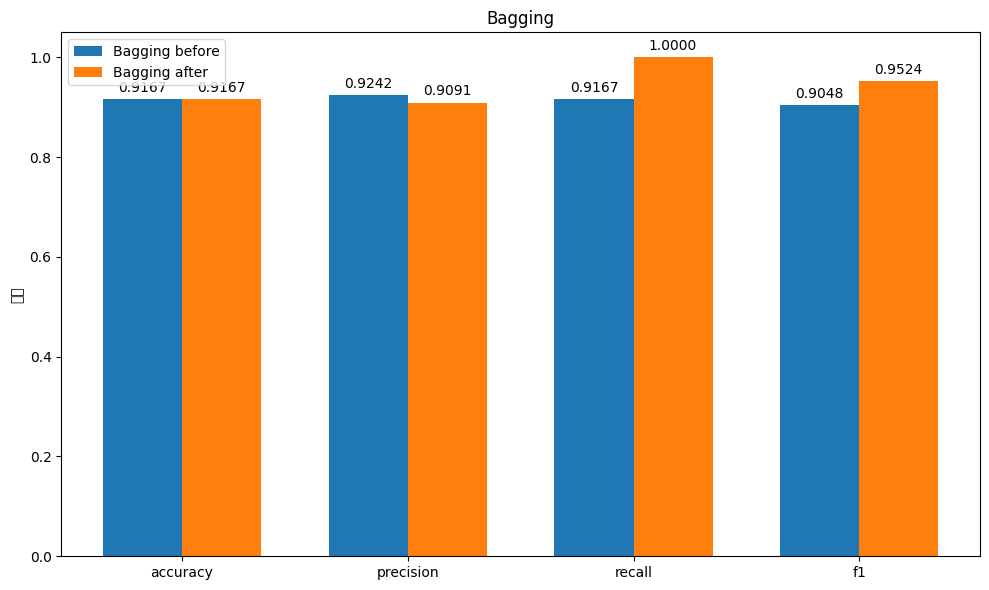

In [23]:
import matplotlib.pyplot as plt
import numpy as np

# 定义评估指标和对应的值
metrics = ['accuracy', 'precision', 'recall', 'f1']
before_bagging = [0.9167, 0.9242, 0.9167, 0.9048]
after_bagging = [0.9167, 0.9091, 1.0000, 0.9524]

# 设置图形大小
plt.figure(figsize=(10, 6))

# 设置柱子的宽度和位置
x = np.arange(len(metrics))
width = 0.35

# 绘制优化前的柱子
rects1 = plt.bar(x - width/2, before_bagging, width, label='Bagging before')

# 绘制优化后的柱子
rects2 = plt.bar(x + width/2, after_bagging, width, label='Bagging after')

# 添加标题和标签
plt.title('Bagging')
plt.ylabel('分数')
plt.xticks(x, metrics)
plt.legend()

# 为每个柱子添加数值标签
def autolabel(rects):
    for rect in rects:
        height = rect.get_height()
        plt.annotate('{:.4f}'.format(height),
                     xy=(rect.get_x() + rect.get_width() / 2, height),
                     xytext=(0, 3),  # 3 points vertical offset
                     textcoords="offset points",
                     ha='center', va='bottom')

autolabel(rects1)
autolabel(rects2)

# 显示图形
plt.tight_layout()
plt.show()